# To be completed at the Data Science Workshop and in your own time.

These set of examples we will help you get familiar with estimating probabilities and using Bayes Theorem within a Jupyter notebook.  The questions coloured green are important practice for CA.

Before attempting these examples, please ensure you have read through [Chapter 4 Jupyter Notebook](https://github.com/itrharrison/PX4146/blob/main/Chapter4/Chapter4.ipynb) and have completed the Learning Central **Chapter 4 quiz**.

These are good practice for CA 1 Question 5.

***

# Errors

## Question

Three students measure the same resistance several times, with final measurements (in Ohms):

Student 1: $R = 11 \pm 1$
Student 2: $R = 12 \pm 1$
Student 3: $R = 10 \pm 3$.

Given these three results what do we write down as the best estimate for the resistance $R$? Tip: you will need to use weighted errors.

### Answer

*Your answer here.*

In [4]:
import numpy as np
R=np.array([11,12,10])
err=np.array([1,1,3])
weight=1/err**2
R_best=np.sum(weight*R)/np.sum(weight)
sigma_best=1/np.sqrt(np.sum(weight))
print(f"Best estimate for R is {R_best:.2f} +/- {sigma_best:.2f} Ohms")

Best estimate for R is 11.42 +/- 0.69 Ohms


***

# Correlation

## <font color=#30a64d>Question </font>

The datafile [worldpopulation.txt](https://github.com/itrharrison/PX4146/blob/main/Chapter4/worldpopulation.txt) contains the world population size measured since 1960. Plot the data (you will need to upload the datafile to your Google Colab). <br><br>

Measure the correlation coefficient using the in built Python package for the Pearson $r$s statistic. <br><br>

Measure it again but this time creating the functions to calculate $r$ from scratch.  

The url of the file is "https://github.com/itrharrison/PX4146/blob/main/Chapter4/worldpopulation.txt"

### Answer

*Your answer here.*

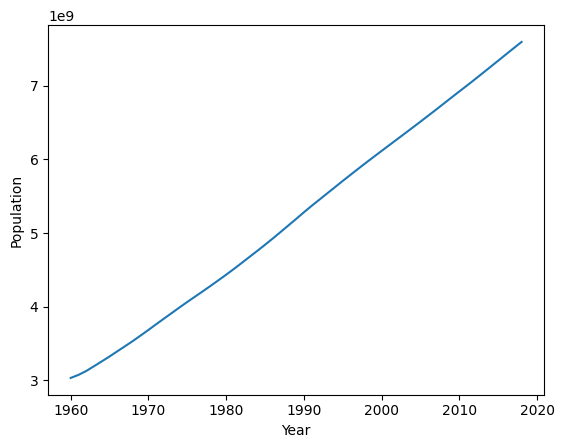

r=0.9995634246126303
r=0.9995634246126304


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# Read using whitespace as delimiter
df=np.loadtxt("worldpopulation.txt")
year = df[0]
pop = df[1]

plt.plot(year, pop)
plt.xlabel("Year")
plt.ylabel("Population")
plt.show()

r, p = pearsonr(year, pop)
print(f"r={r}")

r = np.sum((year - np.mean(year)) * (pop - np.mean(pop))) / np.sqrt(np.sum((year - np.mean(year))**2) * np.sum((pop - np.mean(pop))**2))
print(f"r={r}")

***

# Hypothesis Testing

## <font color=#30a64d>Question</font>

A company releases a new ski wax that it claims (naturally) is superior to its rivals, and greatly reduces the friction between skis and snow. A skiing magazine decides to test the claim by performing an experiment. They take 10 pairs of skis, and treat one ski from each pair -- the left one -- with the new wax, and the other (the right) ski with the wax from a competing brand. Each pair of skis are then released from the top of a ramp in turn, and they record which of the two skis reach the bottom of the ramp first.    The team find that the new skis win 8 of the 10 races.  Is their claim correct?

### Answer

*Your answer here.*

Hypotheses:
* $H_0$: The new wax is no better than the competing one, so each ski has a 50% chance of winning.
* $H_1$: The new wax is better, so chance is greater than 50% of winning.

There have been 8 wins out of 10 races.

In [14]:
from scipy.stats import binom
X = binom(10, 0.5)
p_8 = X.pmf(8)
p_8_or_more = 1 - X.cdf(7)

print(f"Probability of exactly 8 wins: {p_8:.4f}")
print(f"Probability of 8 or more wins (p-value): {p_8_or_more:.4f}")

Probability of exactly 8 wins: 0.0439
Probability of 8 or more wins (p-value): 0.0547


Since the p-value is $p>0.05$ cant fully reject $H_0$.

***